In [1]:
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt

import Minimal_Model_1D as M

In [2]:
###defining constants##

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

checking convergence for width of 100 nm

In [7]:
NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands

first subband energy = 0.6101182522944013 
 second subband energy = 1.2202365045888026


In [8]:
K = 4

Tot = 30

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, epsilon=0)
    H = D.H_sys(PHI, so='li')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)

0
5
10
15
20
25


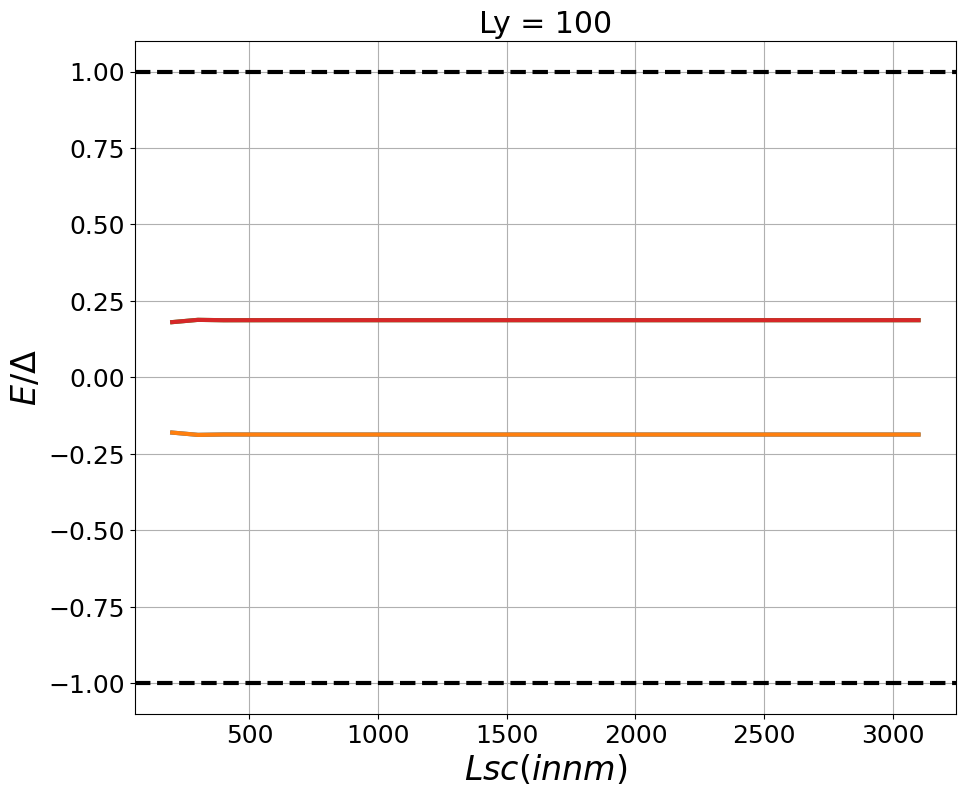

In [10]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [11]:
Ep2 = Ep[:,3]

In [12]:

for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

0.18061551130124245
200 0
0.18808736041980556
300 1
0.1868359440521615
400 2
0.1869118203500495
500 3
0.18697272833015197
600 4
0.18698179124618383
700 5
0.18698353292824246
800 6
0.1869817579404204
900 7
0.18698064163450775
1000 8
0.18698044392081878
1100 9
0.1869805420911885
1200 10
0.1869806211241711
1300 11
0.18698063903726456
1400 12
0.18698063312183763
1500 13
0.18698062742268134
1600 14
0.18698062599095408
1700 15
0.18698062637673796
1800 16
0.18698062679672664
1900 17
0.186980626909571
2000 18
0.1869806268835278
2100 19
0.18698062685211797
2200 20
0.18698062684318398
2300 21
0.18698062684494174
2400 22
0.186980626847307
2500 23
0.18698062684801378
2600 24
0.18698062684789388
2700 25
0.18698062684770922
2800 26
0.18698062684767705
2900 27
0.1869806268476778
3000 28


Checking convergence for width of 10 nm

In [13]:
NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands

first subband energy = 61.011825229440134 
 second subband energy = 122.02365045888027


0
5
10
15
20
25


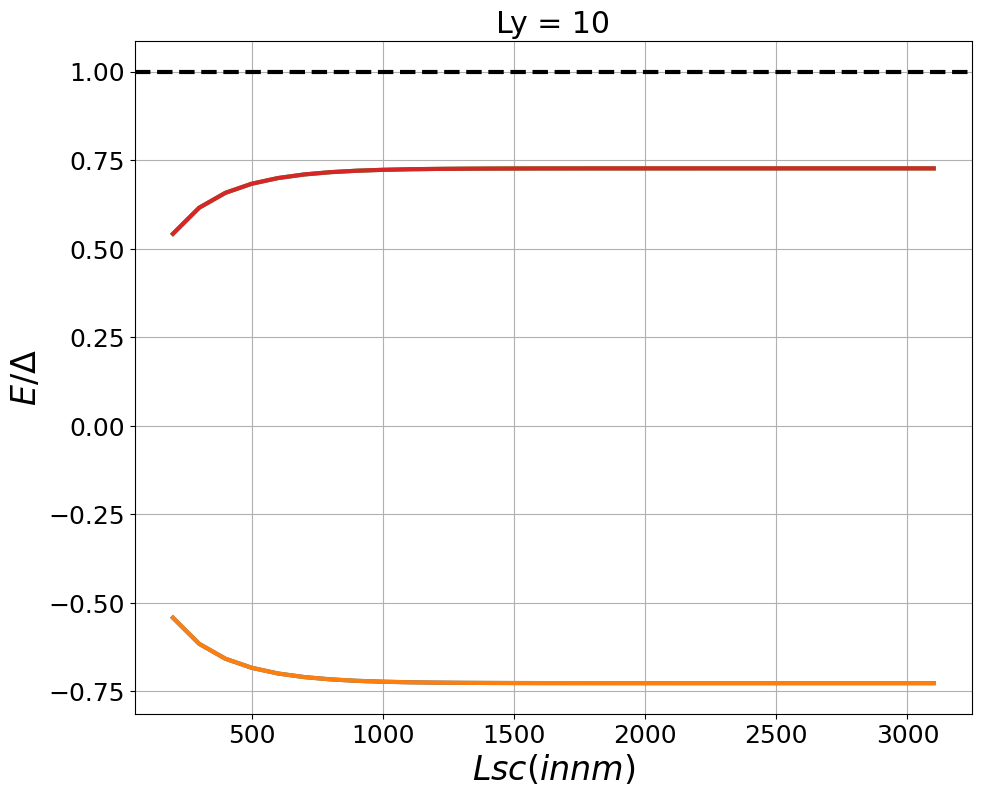

In [14]:
K = 4

Tot = 30

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM, epsilon=0)
    H = D.H_sys(PHI, so='li')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)


plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [15]:
Ep2 = Ep[:,3]


for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

0.7095192107997323
700 5
0.7159784736652283
800 6
0.7200534737247438
900 7
0.7226038240053109
1000 8
0.7241862522037249
1100 9
0.7251599677912031
1200 10
0.7257545362138434
1300 11
0.726115039597927
1400 12
0.7263321890267259
1500 13
0.7264621626114078
1600 14
0.7265394660853309
1700 15
0.7265851419253525
1800 16
0.7266119402664925
1900 17
0.7266275407737482
2000 18
0.7266365423732267
2100 19
0.7266416830360218
2200 20
0.7266445828379001
2300 21
0.7266461940450628
2400 22
0.7266470722808022
2500 23
0.7266475390341428
2600 24
0.7266477785216318
2700 25
0.726647895088894
2800 26
0.7266479470143032
2900 27
0.7266479662771202
3000 28


Convergence lengths for linear SO of 20 meV-nm, weak link length of 300 nm and chemical potential of 1+OMEGA meV is:
for Ly = 100 nm ~ 200 nm SC on both sides
for Ly = 10 nm ~ 700 nm of SC on both sides

Now plotting E vs phi ABS for linear SO of 20 meV nm and weak link length 300 nm 

In [16]:
NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1000
N = 2*NSC + NSM
#PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands



first subband energy = 61.011825229440134 
 second subband energy = 122.02365045888027


In [17]:

PHI = np.linspace(-1*np.pi,1*np.pi,51)
K = 8

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    #DELTA = np.array([1,0,1*cmath.exp(1j*PHI[i])])
    
    H = D.H_sys(PHI[i], so='li' )
    #print(i)
    #+ KxSq(N, M, AX, PX, KX[i])
    #H = KxSqKy(N,M,AX,AY,PX,PY,KX[i],KY[i])
    #H = H.toarray()
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    #print('a')
    #print(E.shape)
    Ep[i,:] =np.sort(E)
    if i%20==0:
        print(i)


0
20
40


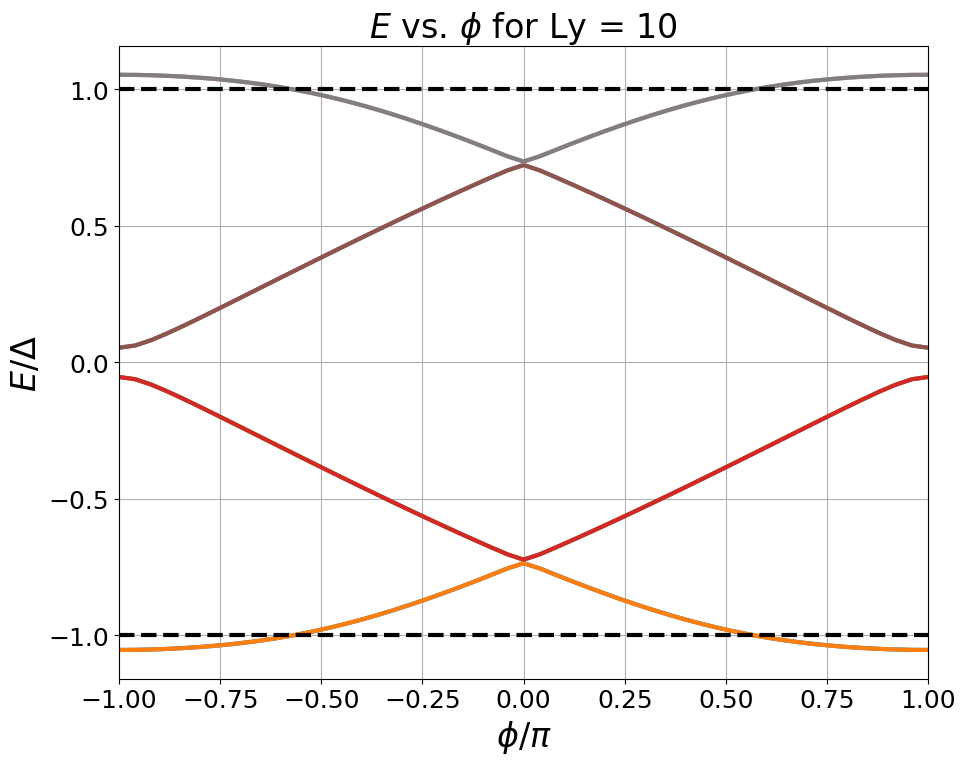

In [18]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,:]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

first subband energy = 0.6101182522944013 
 second subband energy = 1.2202365045888026
0
20
40


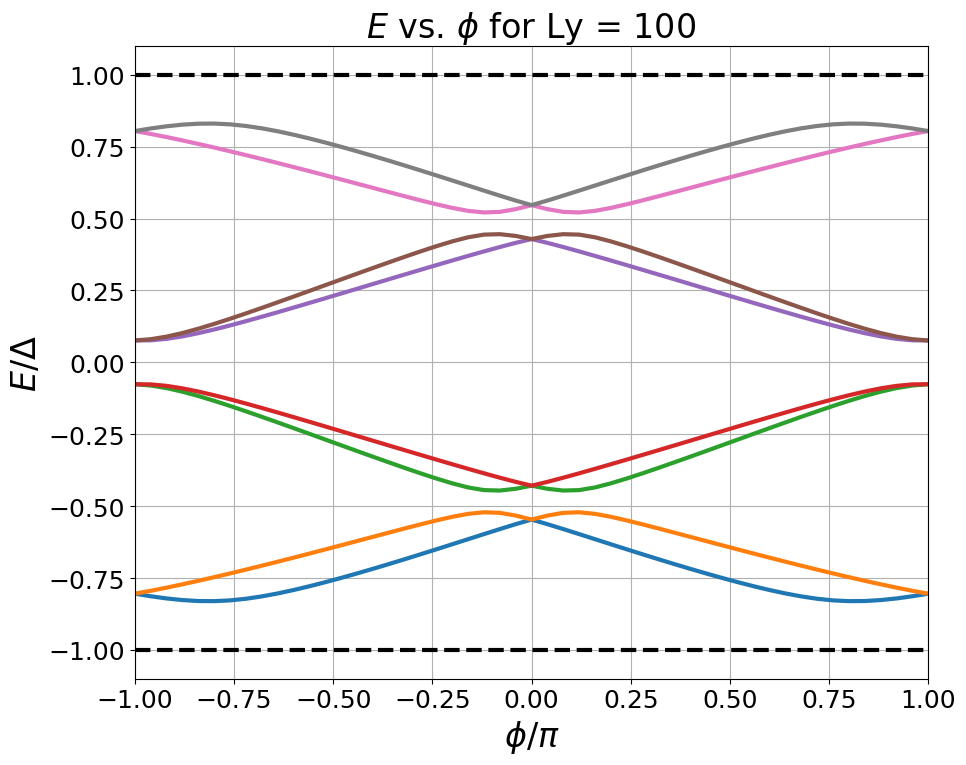

In [19]:
NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 20        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
NSC = 1000
N = 2*NSC + NSM
#PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.05 + OMEGA   #in between two subbands
MU_SM =  0.05 + OMEGA   #in between two subbands


PHI = np.linspace(-1*np.pi,1*np.pi,51)
K = 8

Ep = np.empty((PHI.shape[0],K))

D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

for i in range(PHI.shape[0]):

    #DELTA = np.array([1,0,1*cmath.exp(1j*PHI[i])])
    
    H = D.H_sys(PHI[i], so='li' )
    #print(i)
    #+ KxSq(N, M, AX, PX, KX[i])
    #H = KxSqKy(N,M,AX,AY,PX,PY,KX[i],KY[i])
    #H = H.toarray()
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    #print('a')
    #print(E.shape)
    Ep[i,:] =np.sort(E)
    if i%20==0:
        print(i)

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,2:6]
Ep2 = Ep[:,:]

for i in range(Ep2.shape[1]):
    #plt.plot(PHI/np.pi, Ep[:,i]/DELTA, lw=3, color=line_colors[i], linestyle=line_styles[i])
    plt.plot(PHI/np.pi, Ep2[:,i]/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$\phi/\pi$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.title(r'$E$ vs. $\phi$ for Ly = %i' %LY, fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
plt.xlim(-1, 1)
#plt.ylim(-0.5, 0.5)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.show()

Now looking at the perturbative regime for linear SO coupling

In [3]:
NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 1000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands

ALPHAT = np.linspace(1, 100, 81)

K = 12

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)


first subband energy = 0.6101182522944013 
 second subband energy = 1.2202365045888026
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


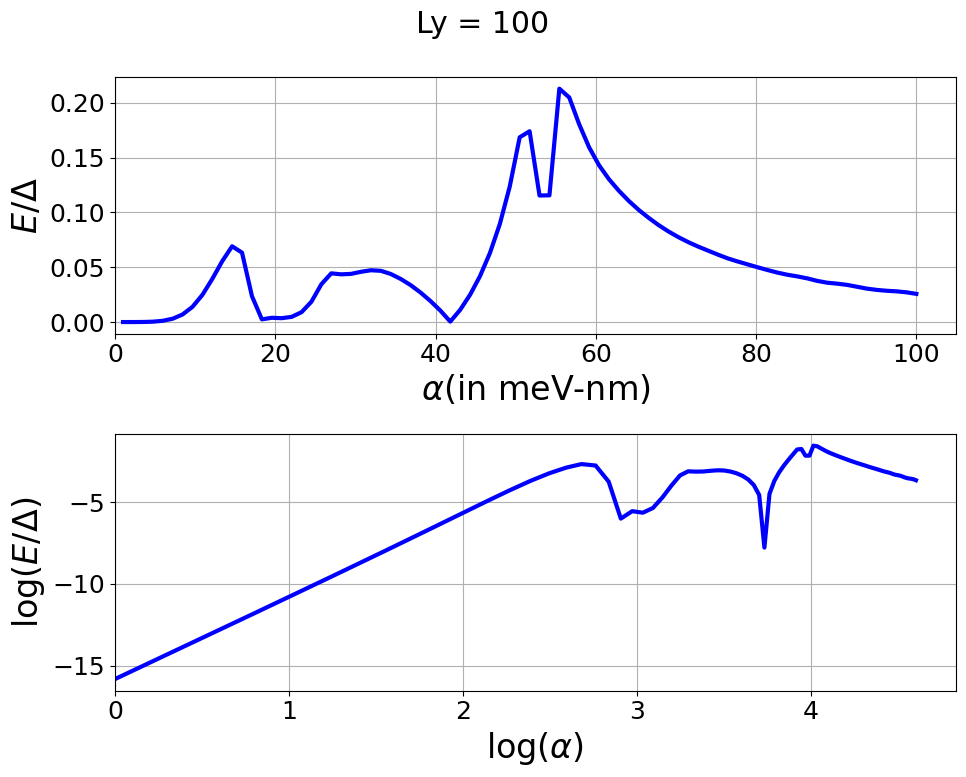

In [21]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [23]:
np.exp(2.5)


12.182493960703473

first subband energy = 61.011825229440134 
 second subband energy = 122.02365045888027
0
5
10
15
20
25
30
35
40
45
50
55
60
65
70
75
80


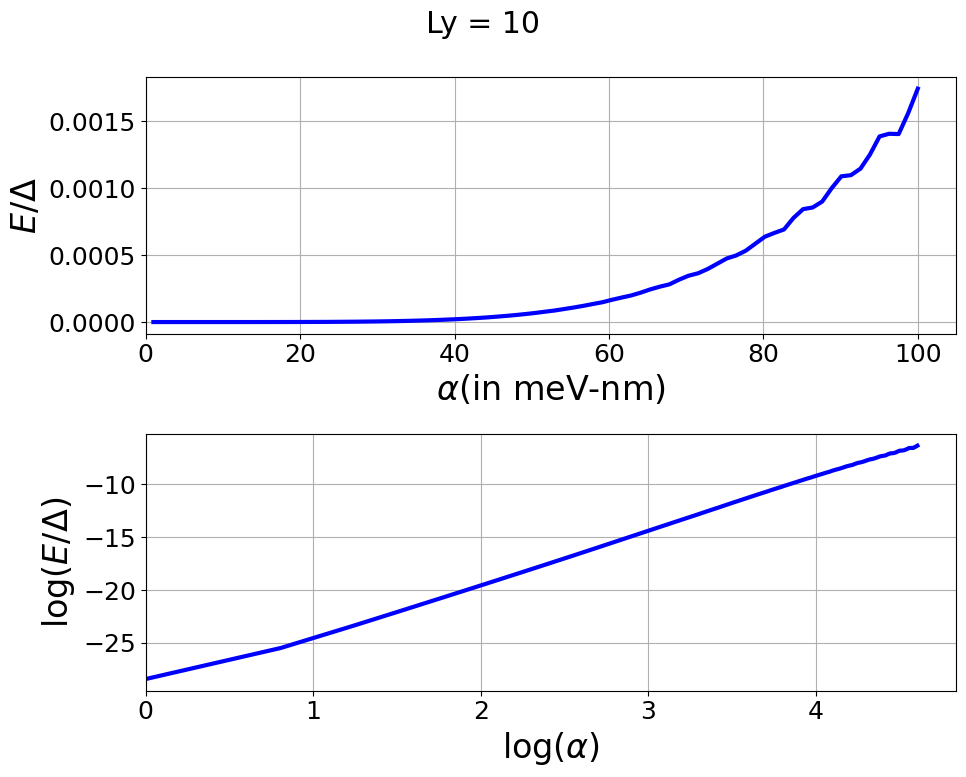

In [24]:
NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

LY = 10           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 1000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.5 + OMEGA   #in between two subbands
MU_SM =  0.5 + OMEGA   #in between two subbands

ALPHAT = np.linspace(1, 100, 81)

K = 12

Ep_li = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fli = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hli = Fli.H_sys(PHI, so = 'li', on_both_junc=False)

    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli
    
    if i%5==0:
        print(i)

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]


plt.subplot(2,1,1)
plt.plot((ALPHAT), (Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(2,1,2)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_li/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [26]:
np.exp(3)

20.085536923187668

In [25]:
np.exp(4)

54.598150033144236

In [27]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

NSC = 1000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 12  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 100, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.5 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.5 + OMEGA

K = 12

Ep_li = np.empty((LY.shape[0],K))
Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)


0
10
20
30
40
50


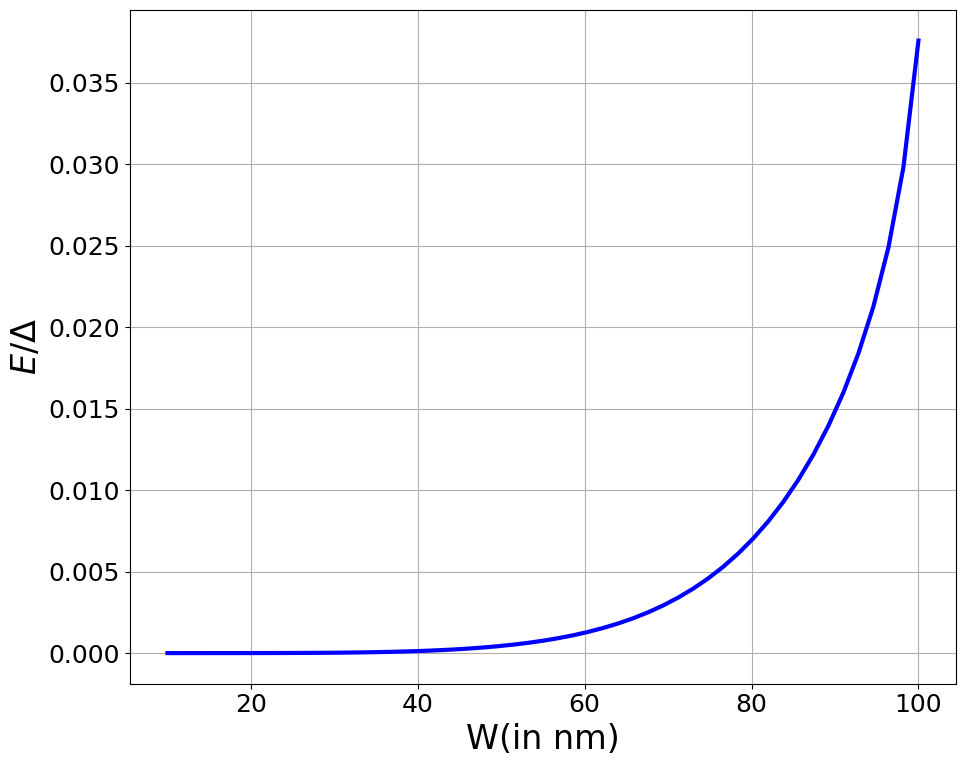

In [28]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

plt.plot(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

In [29]:
### Plotting spin splitting while varying width ###

NSM = 300          # in nm
MY = 4             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

NSC = 1000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 12  #meV-nm # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 200, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.5 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.5 + OMEGA

K = 12

Ep_li = np.empty((LY.shape[0],K))
Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fli = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hli = Fli.H_sys(PHI, so = 'li')
    
    Eli = eigsh(Hli ,k=K,sigma=0, return_eigenvectors=False)
    
    Eli = np.sort(Eli)
    
    Ep_li[i,:] = Eli 
    
    if i%10==0:
        print(i)


0
10
20
30
40
50


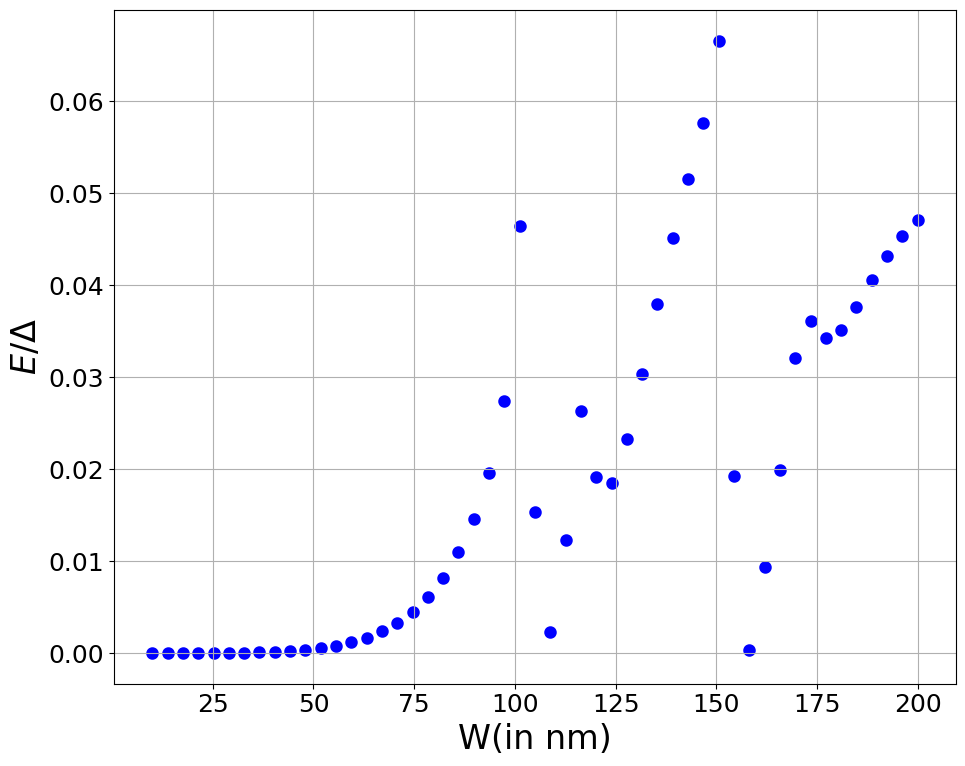

In [31]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_li = Ep_li[:,K//2+1] - Ep_li[:,K//2]

plt.scatter(LY, Ep_Split_li/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()